In [2]:
# Install Plotly (optional if not installed)
!pip install plotly --quiet


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set(style="whitegrid")


In [4]:
!pip install kagglehub --quiet
import kagglehub, os

path = kagglehub.dataset_download("yasserh/titanic-dataset")
df = pd.read_csv(os.path.join(path, "Titanic-Dataset.csv"))
df.head()


100%|██████████| 22.0k/22.0k [00:00<00:00, 9.41MB/s]

Extracting files...


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Basic structure
df.info()

# Numerical summary
df.describe(include='all').T

# Count of nulls
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


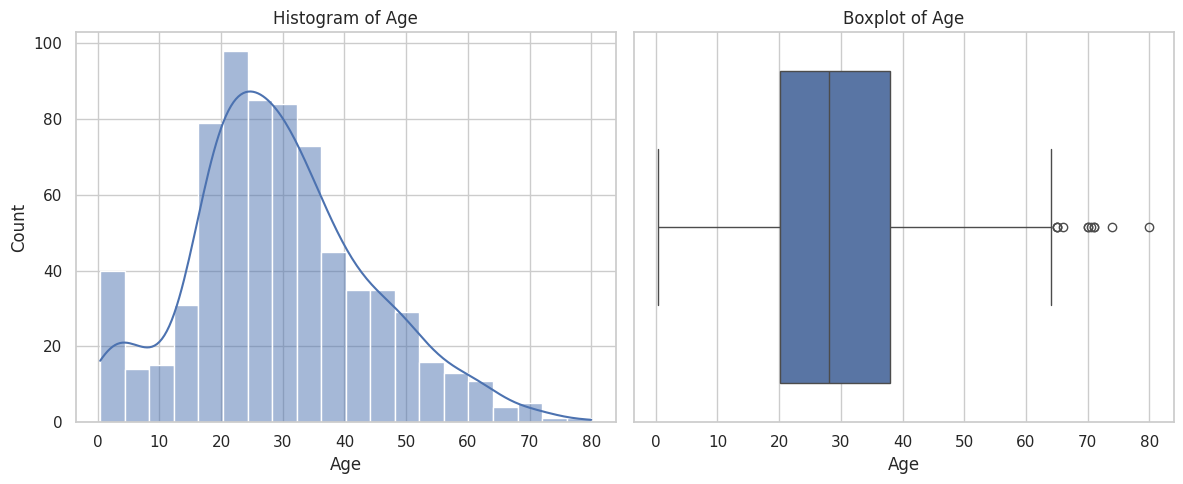

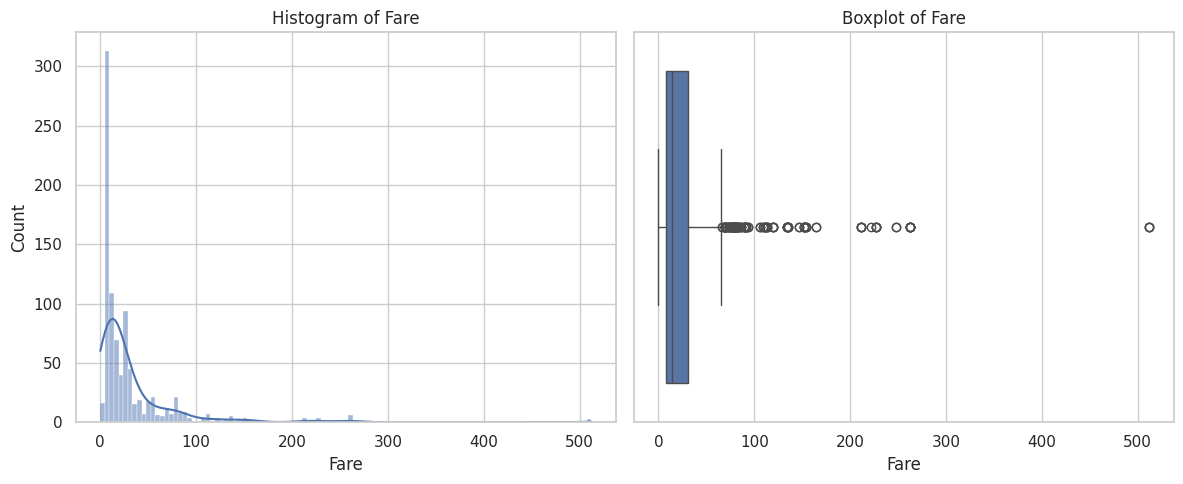

In [6]:
# Age
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Age'].dropna(), kde=True)
plt.title("Histogram of Age")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['Age'])
plt.title("Boxplot of Age")
plt.tight_layout()
plt.show()
# Fare
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Fare'].dropna(), kde=True)
plt.title("Histogram of Fare")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['Fare'])
plt.title("Boxplot of Fare")
plt.tight_layout()
plt.show()


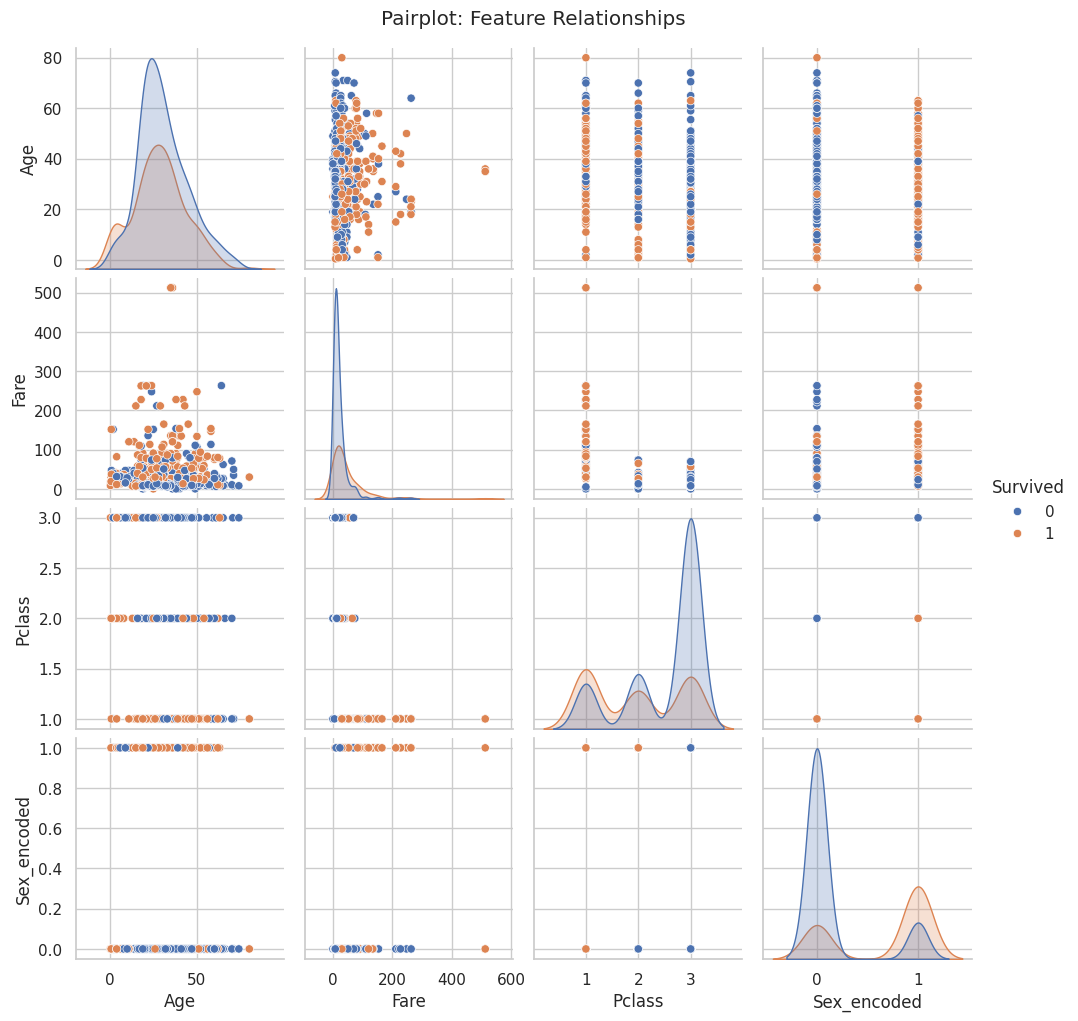

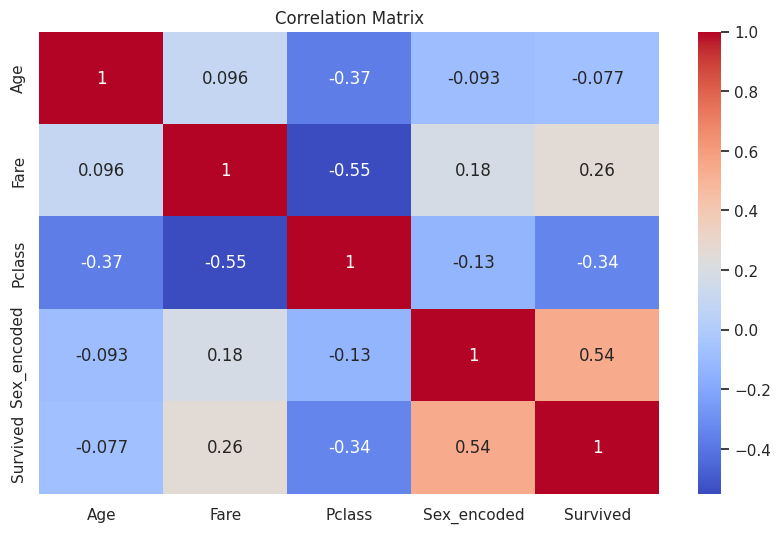

In [7]:
# Convert categorical 'Sex' for plotting
df['Sex_encoded'] = df['Sex'].map({'male': 0, 'female': 1})

# Pairplot (can take time if large dataset)
sns.pairplot(df[['Age', 'Fare', 'Pclass', 'Sex_encoded', 'Survived']], hue='Survived')
plt.suptitle("Pairplot: Feature Relationships", y=1.02)
plt.show()
# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df[['Age', 'Fare', 'Pclass', 'Sex_encoded', 'Survived']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()


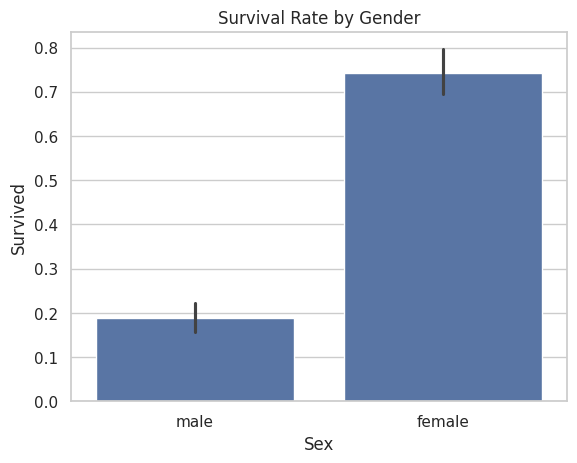

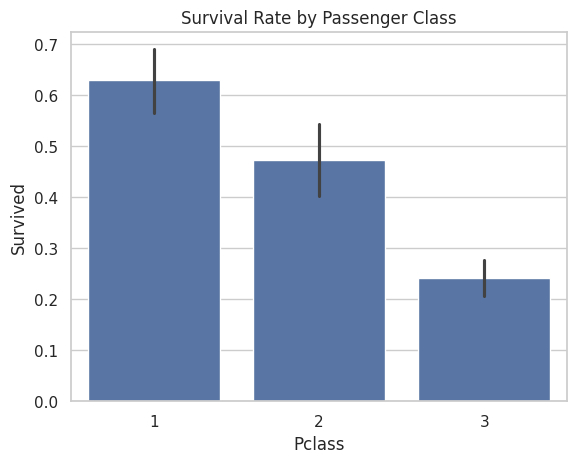

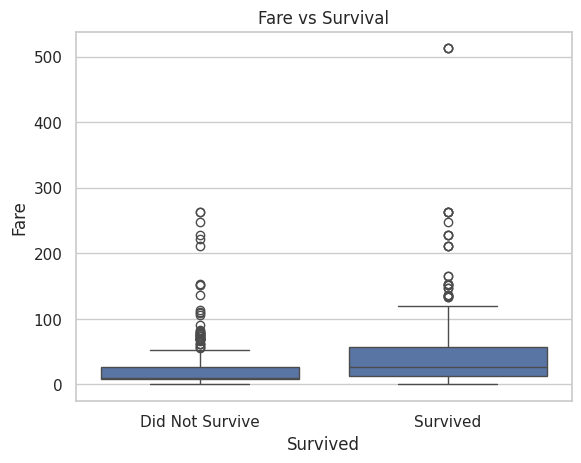

In [8]:
sns.barplot(x='Sex', y='Survived', data=df)
plt.title("Survival Rate by Gender")
plt.show()
sns.barplot(x='Pclass', y='Survived', data=df)
plt.title("Survival Rate by Passenger Class")
plt.show()
sns.boxplot(x='Survived', y='Fare', data=df)
plt.title("Fare vs Survival")
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.show()


In [9]:
fig = px.histogram(df, x="Fare", color="Survived", nbins=50, title="Fare Distribution by Survival")
fig.show()
